# Nhóm: Nguyễn Minh Khánh - 2470260 & Trương Minh Sơn - 2370273

# BT1

## Đề bài
Use the simplex method to solve the following linear program
**Maximize:**  
$$ Z = x_1 + x_2 + 3x_3 $$

**Subject to:**  
$$ x_1 + x_3 = 1 $$
$$ x_2 + x_3 = 2 $$
$$ x_1, x_2, x_3 \ge 0 $$

---

**1. Thiết lập bài toán**

* **Hàm mục tiêu:** $\max Z = x_1 + x_2 + 3x_3$


* **Hệ điều kiện ràng buộc:**
* $x_1 + x_3 = 1$


* $x_2 + x_3 = 2$


* $x_1, x_2, x_3 \ge 0$





Từ hệ ràng buộc, ta thấy các biến $x_1$ và $x_2$ đã có hệ số tạo thành ma trận đơn vị $\begin{pmatrix} 1 & 0 \\ 0 & 1 \end{pmatrix}$. Do đó, ta có thể chọn $x_1$ và $x_2$ làm biến cơ sở (Basic Variables - BV) ban đầu, và $x_3$ là biến phi cơ sở ($x_3 = 0$).

Để đưa vào bảng đơn hình, ta cần biểu diễn hàm mục tiêu theo biến phi cơ sở $x_3$.

Từ hệ ràng buộc: $x_1 = 1 - x_3$ và $x_2 = 2 - x_3$.
Thay vào hàm mục tiêu: $Z = (1 - x_3) + (2 - x_3) + 3x_3 = 3 + x_3 \Rightarrow Z - x_3 = 3$.

**2. Bảng đơn hình khởi tạo**

| Cơ sở | $Z$ | $x_1$ | $x_2$ | $x_3$ | RHS (Hằng số) | Tỷ số (Ratio) |
| --- | --- | --- | --- | --- | --- | --- |
| **$Z$** | 1 | 0 | 0 | -1 | 3 |  |
| **$x_1$** | 0 | 1 | 0 | 1 | 1 | $1/1 = 1$ |
| **$x_2$** | 0 | 0 | 1 | 1 | 2 | $2/1 = 2$ |

* **Biến vào:** Ở dòng $Z$, hệ số âm nhất là $-1$ (tại cột $x_3$). Vậy $x_3$ là biến đưa vào cơ sở.
* **Biến ra:** Xét tỷ số dương nhỏ nhất: $\min(1/1, 2/1) = 1$ (tại dòng $x_1$). Vậy $x_1$ là biến đưa ra khỏi cơ sở. Phần tử trục trặc (pivot) là 1 (giao của dòng $x_1$ và cột $x_3$).

**3. Vòng lặp 1 (Xoay quanh phần tử pivot)**

Thực hiện các phép biến đổi dòng:

* Dòng $x_3$ mới = Dòng $x_1$ cũ.
* Dòng $Z$ mới = Dòng $Z$ cũ + Dòng $x_3$ mới.
* Dòng $x_2$ mới = Dòng $x_2$ cũ - Dòng $x_3$ mới.

Ta được bảng đơn hình thứ 2:

| Cơ sở | $Z$ | $x_1$ | $x_2$ | $x_3$ | RHS (Hằng số) |
| --- | --- | --- | --- | --- | --- |
| **$Z$** | 1 | 1 | 0 | 0 | 4 |
| **$x_3$** | 0 | 1 | 0 | 1 | 1 |
| **$x_2$** | 0 | -1 | 1 | 0 | 1 |

**4. Kết luận**
Trên dòng $Z$, tất cả các hệ số của $x_1, x_2, x_3$ đều lớn hơn hoặc bằng 0 (lần lượt là $1, 0, 0$). Bảng đơn hình đã đạt trạng thái tối ưu.

Giải pháp tối ưu của bài toán là:

* $x_1 = 0$
* $x_2 = 1$
* $x_3 = 1$
* **Giá trị lớn nhất $\max Z = 4$**

In [2]:
def print_tableau(tableau, iteration):
    print(f"\n--- Bảng đơn hình (Vòng lặp {iteration}) ---")
    print(f"{'x1':>6} | {'x2':>6} | {'x3':>6} | {'RHS':>6}")
    print("-" * 33)
    for row in tableau[:-1]:
        print(f"{row[0]:6.2f} | {row[1]:6.2f} | {row[2]:6.2f} | {row[3]:6.2f}")
    print("-" * 33)
    Z_row = tableau[-1]
    print(f"{Z_row[0]:6.2f} | {Z_row[1]:6.2f} | {Z_row[2]:6.2f} | {Z_row[3]:6.2f} (Z)")

def solve_simplex(tableau):
    num_rows = len(tableau)
    num_cols = len(tableau[0])
    iteration = 0

    print_tableau(tableau, iteration)

    while True:
        # Kiểm tra điều kiện tối ưu: tất cả hệ số dòng Z (trừ cột RHS) >= 0
        z_row = tableau[-1][:-1]
        if all(coeff >= 0 for coeff in z_row):
            print("\nĐã optimize!")
            break

        iteration += 1

        # 1. Tìm biến vào (cột chứa giá trị âm nhỏ nhất ở dòng Z)
        entering_col = z_row.index(min(z_row))

        # 2. Tìm biến ra (dòng có tỷ số RHS / hệ số dương nhỏ nhất)
        min_ratio = float('inf')
        leaving_row = -1

        for i in range(num_rows - 1): # Chỉ xét các dòng ràng buộc, bỏ dòng Z
            if tableau[i][entering_col] > 0:
                ratio = tableau[i][-1] / tableau[i][entering_col]
                if ratio < min_ratio:
                    min_ratio = ratio
                    leaving_row = i

        if leaving_row == -1:
            print("\nBài toán không giới hạn (Unbounded).")
            return None

        # 3. Phép biến đổi dòng (Xoay quanh phần tử pivot)
        pivot = tableau[leaving_row][entering_col]

        # Chia dòng chứa biến ra cho phần tử pivot để pivot thành 1
        tableau[leaving_row] = [val / pivot for val in tableau[leaving_row]]

        # Biến đổi các dòng còn lại để các phần tử trên cột pivot thành 0
        for i in range(num_rows):
            if i != leaving_row:
                factor = tableau[i][entering_col]
                tableau[i] = [tableau[i][j] - factor * tableau[leaving_row][j] for j in range(num_cols)]

        print_tableau(tableau, iteration)

    return tableau

# Thiết lập bảng đơn hình ban đầu (như đã phân tích ở phần giải tay)
# Các cột tương ứng: x1, x2, x3, RHS (Hằng số)
# Dòng 1: x1 + 0*x2 + 1*x3 = 1
# Dòng 2: 0*x1 + 1*x2 + 1*x3 = 2
# Dòng 3: 0*x1 + 0*x2 - 1*x3 = 3 (Phương trình hàm mục tiêu Z - x3 = 3)
initial_tableau = [
    [1.0, 0.0, 1.0, 1.0],
    [0.0, 1.0, 1.0, 2.0],
    [0.0, 0.0, -1.0, 3.0]
]

# Run
final_tableau = solve_simplex(initial_tableau)

if final_tableau:
    # Trích xuất kết quả fr. optimized table
    max_z = final_tableau[-1][-1]

    # Biến cơ sở tại cột tương ứng sẽ có một số 1 duy nhất và các số 0 còn lại
    def get_variable_value(col_index, tableau):
        col_vals = [row[col_index] for row in tableau[:-1]]
        if col_vals.count(1.0) == 1 and col_vals.count(0.0) == len(col_vals) - 1:
            return tableau[col_vals.index(1.0)][-1]
        return 0.0

    x1 = get_variable_value(0, final_tableau)
    x2 = get_variable_value(1, final_tableau)
    x3 = get_variable_value(2, final_tableau)

    print("\nKết quả bài toán:")
    print(f"Max Z = {max_z:.2f}")
    print(f"x1 = {x1:.2f}")
    print(f"x2 = {x2:.2f}")
    print(f"x3 = {x3:.2f}")


--- Bảng đơn hình (Vòng lặp 0) ---
    x1 |     x2 |     x3 |    RHS
---------------------------------
  1.00 |   0.00 |   1.00 |   1.00
  0.00 |   1.00 |   1.00 |   2.00
---------------------------------
  0.00 |   0.00 |  -1.00 |   3.00 (Z)

--- Bảng đơn hình (Vòng lặp 1) ---
    x1 |     x2 |     x3 |    RHS
---------------------------------
  1.00 |   0.00 |   1.00 |   1.00
 -1.00 |   1.00 |   0.00 |   1.00
---------------------------------
  1.00 |   0.00 |   0.00 |   4.00 (Z)

Đã optimize!

Kết quả bài toán:
Max Z = 4.00
x1 = 0.00
x2 = 1.00
x3 = 1.00


# BT2

## Đề bài (Consider the linear program)
**Maximize:**  
$$ Z = 2x_1 + x_2 $$

**Subject to:**  
$$ 0 \leq x_1 \leq 5 $$
$$ 0 \leq x_2 \leq 7 $$
$$ x_1 + x_2 \leq 9 $$

Convert the problem to standard form and solve it using the simplex method.

---

## 1. Dạng chuẩn (Standard form)
Thêm các biến bù (slack variables) $s_1, s_2, s_3$ để chuyển các bất phương trình thành phương trình:
$$ x_1 + s_1 = 5 $$
$$ x_2 + s_2 = 7 $$
$$ x_1 + x_2 + s_3 = 9 $$
Với điều kiện: $x_1, x_2, s_1, s_2, s_3 \geq 0$

---

## 2. Giải bằng phương pháp Đơn hình (Simplex Method)

### Bảng Simplex khởi tạo

| Cơ sở | $Z$ | $x_1$ | $x_2$ | $s_1$ | $s_2$ | $s_3$ | RHS | Tỷ số |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :--- |
| **$Z$** | 1 | -2 | -1 | 0 | 0 | 0 | 0 | |
| **$s_1$** | 0 | 1 | 0 | 1 | 0 | 0 | 5 | $5/1 = 5$ |
| **$s_2$** | 0 | 0 | 1 | 0 | 1 | 0 | 7 | $7/0$ |
| **$s_3$** | 0 | 1 | 1 | 0 | 0 | 1 | 9 | $9/1 = 9$ |

*   **Biến vào:** $x_1$ (có hệ số âm lớn nhất ở dòng Z, là -2).
*   **Biến ra:** $s_1$ (tỷ số RHS/$x_1$ dương nhỏ nhất, $5 < 9$).
*   **Phần tử xoay (Pivot):** Giao của cột $x_1$ và hàng $s_1$, có giá trị là 1.

---

### Bảng sau vòng lặp 1 (Biến vào $x_1$, biến ra $s_1$)
Làm cho phần tử xoay bằng 1 (đã là 1). Các phần tử khác trong cột $x_1$ thành 0 bằng cách thực hiện phép toán trên hàng.
*   **Hàng $x_1$:** Giữ nguyên do hệ số xoay là 1.
*   **Hàng $Z$ mới** = Hàng $Z$ cũ - (-2) * Hàng $x_1$ mới = Hàng $Z$ cũ + 2 * Hàng $x_1$ mới.
*   **Hàng $s_2$ mới:** Hệ số $x_1$ ở hàng $s_2$ đã là 0, nên giữ nguyên.
*   **Hàng $s_3$ mới** = Hàng $s_3$ cũ - 1 * Hàng $x_1$ mới.

| Cơ sở | $Z$ | $x_1$ | $x_2$ | $s_1$ | $s_2$ | $s_3$ | RHS | Tỷ số |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :--- |
| **$Z$** | 1 | 0 | -1 | 2 | 0 | 0 | 10 | |
| **$x_1$** | 0 | 1 | 0 | 1 | 0 | 0 | 5 | $5/0$ |
| **$s_2$** | 0 | 0 | 1 | 0 | 1 | 0 | 7 | $7/1 = 7$ |
| **$s_3$** | 0 | 0 | 1 | -1 | 0 | 1 | 4 | $4/1 = 4$ |

*(Chi tiết phép tính: Hàng Z: -2 -(-2*1)=0; -1 -(-2*0)=-1; 0-(-2*1)=2; 0-(-2*5)=10. Hàng s3: 1-(1*1)=0; 1-(0*1)=1; 0-(1*1)=-1; 9-(1*5)=4)*

*   **Biến vào:** $x_2$ (có hệ số âm lớn nhất ở dòng Z, là -1).
*   **Biến ra:** $s_3$ (tỷ số RHS/$x_2$ dương nhỏ nhất, $4 < 7$).
*   **Phần tử xoay (Pivot):** Giao của cột $x_2$ và hàng $s_3$, có giá trị là 1.

---

### Bảng sau vòng lặp 2 (Biến vào $x_2$, biến ra $s_3$)
*   **Hàng $x_2$ mới (từ hàng $s_3$):** Giữ nguyên do hệ số xoay là 1.
*   **Hàng $Z$ mới** = Hàng $Z$ cũ - (-1) * Hàng $x_2$ mới = Hàng $Z$ cũ + Hàng $x_2$ mới.
*   **Hàng $x_1$ mới:** Do hệ số của $x_2$ ở hàng $x_1$ đã là 0 nên giữ nguyên.
*   **Hàng $s_2$ mới** = Hàng $s_2$ cũ - 1 * Hàng $x_2$ mới.

| Cơ sở | $Z$ | $x_1$ | $x_2$ | $s_1$ | $s_2$ | $s_3$ | RHS | Tỷ số |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :--- |
| **$Z$** | 1 | 0 | 0 | 1 | 0 | 1 | 14 | |
| **$x_1$** | 0 | 1 | 0 | 1 | 0 | 0 | 5 | - |
| **$s_2$** | 0 | 0 | 0 | 1 | 1 | -1 | 3 | |
| **$x_2$** | 0 | 0 | 1 | -1 | 0 | 1 | 4 | |

*(Chi tiết phép tính: Hàng Z: -1 -(-1*1)=0; 2-(-1*-1)=1; 0-(-1*1)=1; 10-(-1*4)=14. Hàng s2: 1-(1*1)=0; 0-(1*-1)=1; 0-(1*1)=-1; 7-(1*4)=3)*

**Kết luận:**
Sau Vòng lặp 2, nhìn vào hàng $Z$ của bảng cuối cùng, tất cả các hệ số của các biến đều $\geq 0$. Điều này cho thấy bảng đã đạt trạng thái tối ưu.
*   Nhìn vào cột RHS của hàng $Z$, ta được giá trị tối đa: **$Z = 14$**.
*   Nhìn vào cột RHS của các biến cơ sở, ta có: **$x_1 = 5$** và **$x_2 = 4$**.

---

## 3. Vẽ đồ thị (Graphical Method)

Từ đồ thị (hình đính kèm trong bài):
*   **Vùng đỏ:** Biểu diễn miền nghiệm của bất phương trình $0 \leq x_1 \leq 5$.
*   **Vùng xanh dương:** Biểu diễn miền nghiệm của bất phương trình $0 \leq x_2 \leq 7$.
*   **Vùng xanh lá:** Biểu diễn miền nghiệm của bất phương trình $x_1 + x_2 \leq 9$.
*   **Đường màu đen:** Đường biểu diễn hàm mục tiêu với giá trị tối ưu: $2x_1 + x_2 = 14$.

Giao điểm tối ưu nằm tại tọa độ $(x_1, x_2) = (5, 4)$, tương ứng với giá trị lớn nhất $Z = 14$.

In [ ]:
# Import các thư viện cần thiết
import scipy.optimize as opt
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Định nghĩa hàm mục tiêu: Maximize Z = 2*x1 + x2 -> Minimize -2*x1 - x2
c = [-2, -1]

# Định nghĩa các điều kiện ràng buộc (A_ub * x <= b_ub)
A_ub = [
    [1, 0],  # 1*x1 + 0*x2 <= 5
    [0, 1],  # 0*x1 + 1*x2 <= 7
    [1, 1]   # 1*x1 + 1*x2 <= 9
]
b_ub = [5, 7, 9]
bounds = [(0, None), (0, None)] # x1 >= 0, x2 >= 0

Nghiệm tối ưu đạt được tại: x1 = 5.00, x2 = 4.00
Giá trị lớn nhất của Z = 14.00



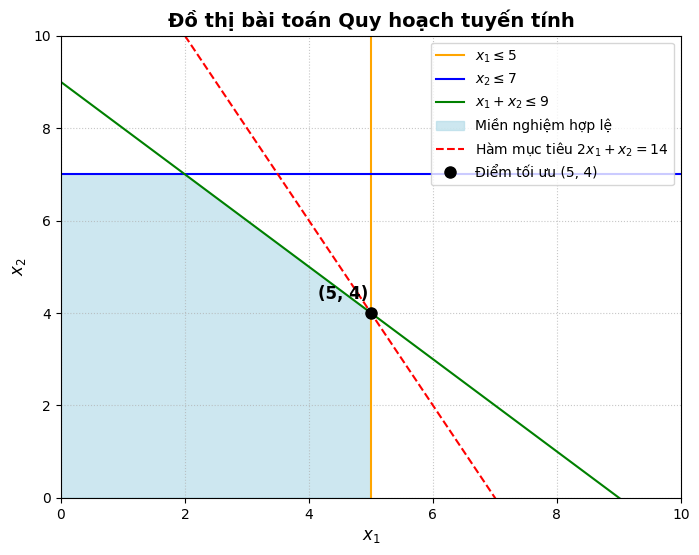

In [ ]:
# Giải bài toán
result = opt.linprog(c=c, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method='highs')

if result.success:
    x1_opt, x2_opt = result.x[0], result.x[1]
    max_Z = -result.fun
    print(f"Nghiệm tối ưu đạt được tại: x1 = {x1_opt:.2f}, x2 = {x2_opt:.2f}")
    print(f"Giá trị lớn nhất của Z = {max_Z:.2f}\n")

    # Thiết lập kích thước khung hình
    plt.figure(figsize=(8, 6))

    # Tạo mảng giá trị x1 từ 0 đến 10 để vẽ đường thẳng
    x_vals = np.linspace(0, 10, 400)

    # Vẽ các đường thẳng ràng buộc
    plt.axvline(5, color='orange', label=r'$x_1 \leq 5$')                        # Đường x1 = 5
    plt.axhline(7, color='blue', label=r'$x_2 \leq 7$')                          # Đường x2 = 7
    plt.plot(x_vals, 9 - x_vals, color='green', label=r'$x_1 + x_2 \leq 9$')     # Đường x1 + x2 = 9

    # Tô màu miền nghiệm hợp lệ (Feasible Region)
    # Các đỉnh được xác định ở bước giải đồ thị: (0,0), (5,0), (5,4), (2,7), (0,7)
    feasible_region = np.array([[0, 0], [5, 0], [5, 4], [2, 7], [0, 7]])
    polygon = plt.Polygon(feasible_region, color='lightblue', alpha=0.6, label='Miền nghiệm hợp lệ')
    plt.gca().add_patch(polygon)

    # Vẽ đường thẳng hàm mục tiêu tối ưu (2*x1 + x2 = 14 => x2 = 14 - 2*x1)
    plt.plot(x_vals, 14 - 2*x_vals, color='red', linestyle='--', label=r'Hàm mục tiêu $2x_1 + x_2 = 14$')

    # Đánh dấu và ghi chú điểm tối ưu trên đồ thị
    plt.plot(x1_opt, x2_opt, 'ko', markersize=8, label=f'Điểm tối ưu ({x1_opt:.0f}, {x2_opt:.0f})')
    plt.annotate(f'({x1_opt:.0f}, {x2_opt:.0f})',
                 (x1_opt, x2_opt), textcoords="offset points",
                 xytext=(-20, 10), ha='center', fontsize=12, fontweight='bold', color='black')

    # Định dạng đồ thị cho dễ nhìn
    plt.xlim(0, 10)
    plt.ylim(0, 10)
    plt.xlabel(r'$x_1$', fontsize=12)
    plt.ylabel(r'$x_2$', fontsize=12)
    plt.title('Đồ thị bài toán Quy hoạch tuyến tính', fontsize=14, fontweight='bold')
    plt.legend(loc='upper right')
    plt.grid(True, linestyle=':', alpha=0.7)

    # Hiển thị đồ thị ra màn hình
    plt.show()

else:
    print("Không tìm thấy nghiệm tối ưu!")